# Neural Pandora's Cluster using REGenerative AutoEncoders (REGAE) trained with Neural Vapor Deposition (NVD)

## Basic stuff

### Basic imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

device = torch.device('cpu')
if torch.cuda.is_available():
    device = torch.device('cuda')
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

torch.autograd.set_detect_anomaly(False)

import logging
import os
import warnings
import shutil
from pathlib import Path

from itertools import chain
import numpy as np
import random
import pickle
torch.__version__

'2.2.2+cu121'

### Basic functions

In [2]:
import os
import requests
from urllib.parse import urlparse

def download_file(url, filename):
    response = requests.get(url)
    if response.status_code == 200:
        with open(filename, 'wb') as file:
            file.write(response.content)
        print(f"File downloaded successfully as {filename}")
    else:
        print(f"Failed to download file from {url}")

def check_or_download_file(file_url, file_filename):
    if os.path.exists(file_filename):
        print(f"{file_filename} already exists in the current folder.")
    else:
        print(f"{file_filename} not found. Downloading from {file_url}...")
        download_file(file_url, file_filename)

In [3]:
from torchvision import transforms
import cv2

def load_image(image_path):
    # Read the RGB image using OpenCV
    image = cv2.imread(image_path)
    # OpenCV reads images in BGR format, so we need to convert it to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return image

def image_to_tensor(image):
    # Convert the image to a torch tensor
    transform = transforms.ToTensor()
    tensor = transform(image)
    return tensor

In [4]:
def count_parameters(network):
    return sum(p.numel() for p in network.parameters() if p.requires_grad)

### Loading image

In [5]:
file_url = "https://stsci-opo.org/STScI-01GQQF9WVPFVMCVHRZY54N2TAR.png"
parsed_url = urlparse(file_url)
file_filename = parsed_url.path[1:]

check_or_download_file(file_url, file_filename)

STScI-01GQQF9WVPFVMCVHRZY54N2TAR.png already exists in the current folder.


In [6]:
rgb_image = load_image(file_filename)
tensor_image = image_to_tensor(rgb_image)
tensor_image_shape = tensor_image.shape

# tensor_image_mean = tensor_image.mean(dim=(1, 2), keepdim=True)
# tensor_image_std = tensor_image.std(dim=(1, 2), keepdim=True)
# tensor_image = (tensor_image - tensor_image_mean) / tensor_image_std

tensor_image = 2 * tensor_image - 1

tensor_image.requires_grad_(False)

tensor_image_shape


libpng warning: iCCP: known incorrect sRGB profile


torch.Size([3, 13422, 17644])

In [7]:
patch_size = 32
compressed_shape = tuple((s // patch_size) for s in tensor_image_shape[1:])

n_pixels = int(np.prod(tensor_image_shape))
n_patches = int(np.prod(compressed_shape))
n_pixels, n_patches, n_pixels / n_patches

(710453304, 230869, 3077.300564389329)

### Image patch functions

In [8]:
def get_image_patch(tensor_image, patch_size, x, y):
    assert 0. <= x < 1. and 0. <= y < 1.
    tensor_image_shape = tensor_image.shape
    img_x = int(x * (tensor_image_shape[1] - patch_size))
    img_y = int(y * (tensor_image_shape[2] - patch_size))
    image_patch = tensor_image[:, img_x:img_x + patch_size, img_y:img_y + patch_size]

    return image_patch.to(device)

In [9]:
image_patch = get_image_patch(tensor_image, patch_size, 0.42, 0.42)
image_patch_shape = image_patch.shape

print(image_patch_shape)
del image_patch

torch.Size([3, 32, 32])


In [10]:
def get_random_patch_batch(batch_size, tensor_image, image_patch_shape=image_patch_shape, patch_size=patch_size):
    image_patch_batch = torch.empty((batch_size,) + image_patch_shape, device=device)
    xs = torch.rand(batch_size, device=device)
    ys = torch.rand(batch_size, device=device)
    for b in range(batch_size):
        image_patch_batch[b] = get_image_patch(tensor_image, patch_size, xs[b].item(), ys[b].item())
    
    return image_patch_batch
    

In [11]:
image_patch_batch = get_random_patch_batch(1, tensor_image)

print(image_patch_batch.shape)
del image_patch_batch

torch.Size([1, 3, 32, 32])


In [12]:
def get_patch_any_size(tensor_image, x_start, x_end, y_start, y_end, tensor_image_shape=tensor_image_shape, patch_size=patch_size):
    image_patch_l = []
    for x in range(x_start, x_end, patch_size):
        for y in range(y_start, y_end, patch_size):
            image_patch = get_image_patch(tensor_image, patch_size, x / tensor_image_shape[1], y / tensor_image_shape[2])
            image_patch_l.append(image_patch)
    
    return torch.stack(image_patch_l)

In [13]:
def reconstruct_image_from_patch_batch(image_patch, rows, cols, channels=3):
    image_patch = image_patch.permute(1, 2, 0, 3)
    image_patch = image_patch.reshape(channels, patch_size, rows, cols * patch_size)
    image_patch = image_patch.permute(0, 2, 1, 3)
    image_patch = image_patch.reshape(channels, rows * patch_size, cols * patch_size)
    return image_patch

In [14]:
def requantize(x):
    qx = x.clamp_(-1, 1).add_(1).mul_(255 / 2).int().clamp_(0, 255)
    return qx.type_as(x).mul_(2 / 255).add_(-1)

## Layers and Networks

### NVD Layers

In [15]:
def crop_tensor(tensor, target_shape):
    slices = tuple(slice(-target_shape[i], tensor.shape[i]) for i in range(len(target_shape)))
    return tensor[slices]


def swap_pairwise(seq):
    return [seq[i+1] if i % 2 == 0 else seq[i-1] for i in range(len(seq))]


def interpolate_tensor(input_tensor, pad):
    current_shape = input_tensor.shape
    pad_rev = tuple(reversed(pad))
    target_shape = [current_shape[i] + pad_rev[2 * i] + pad_rev[2 * i + 1] for i in range(len(current_shape))]

    interpolated_tensor = input_tensor.clone()

    for dim in range(len(current_shape)):
        if interpolated_tensor.shape[dim] != target_shape[dim]:
            # Permute to move the current dimension to the last
            permute_order = list(range(len(current_shape)))
            permute_order.append(permute_order.pop(dim))
            permuted_tensor = interpolated_tensor.permute(permute_order)

            # Reshape to (-1, C)
            reshaped_tensor = permuted_tensor.reshape(-1, permuted_tensor.shape[-1])

            # Interpolate
            reshaped_tensor = F.interpolate(reshaped_tensor.unsqueeze(1), size=target_shape[dim], mode='linear', align_corners=True).squeeze(1)

            # Reshape back to original permuted shape
            permuted_tensor = reshaped_tensor.reshape(*permuted_tensor.shape[:-1], target_shape[dim])

            # Permute back to original order
            inverse_permute_order = [permute_order.index(i) for i in range(len(current_shape))]
            interpolated_tensor = permuted_tensor.permute(inverse_permute_order)

    return interpolated_tensor


class NVD_Module(nn.Module):
    def __init__(self, grow_in, grow_out, fix_in, fix_out, *args, **kwargs):
        super(NVD_Module, self).__init__(*args, **kwargs)

        self.register_buffer('grow_in', torch.tensor((grow_in,)))
        self.register_buffer('grow_out', torch.tensor((grow_out,)))

        self.fix_in = fix_in
        self.fix_out = fix_out

        self.nvd_params = {}

    def register_nvd_parameter(self, param_name, param_shape, pad_shape_func):
        self.register_parameter(param_name, nn.Parameter(torch.nn.init.xavier_normal_(torch.empty(*param_shape)) if len(param_shape) > 1 else torch.randn(param_shape[0]) / param_shape[0]))
        self.register_buffer(f'{param_name}_grad_mask', torch.zeros(*param_shape))
        # # self.register_buffer(f'{param_name}_grad_mask_updatable', torch.zeros([]))
        
        self.nvd_params[param_name] = pad_shape_func, param_shape
    
    def grow(self):
        with torch.no_grad():
            grow_in = 0 if self.fix_in else self.grow_in.item()
            grow_out = 0 if self.fix_out else self.grow_out.item()

            for param_name, (pad_shape_func, base_param_shape) in self.nvd_params.items():

                pad_shape = pad_shape_func(grow_in, grow_out)
                    
                param = self.get_parameter(param_name)
                param_padded = F.pad(param, pad_shape, 'constant', 0.)

                param_init = crop_tensor(param, base_param_shape)
                param_init = 0.9 * param_init + 0.1 * torch.randn_like(param_init) * param_init.std()
                param_init *= -1

                param_padded_corner = crop_tensor(param_padded, base_param_shape) 
                param_padded_corner.copy_(param_init)

                # assert (param_padded_corner == crop_tensor(param_padded, base_param_shape)).all()
                
                init_mask = (param_padded == 0.).float()
                param_padded = (1 - init_mask) * param_padded + init_mask * 1e-2 * torch.randn_like(param_padded) * param_init.std()
                
                self.register_parameter(param_name, nn.Parameter(param_padded))
                del param

                grad_mask = self.get_buffer(f'{param_name}_grad_mask')
                grad_mask_new = F.pad(torch.ones_like(grad_mask), pad_shape, 'constant', 0.)
                
                self.register_buffer(f'{param_name}_grad_mask', grad_mask_new)
                del grad_mask

                # # self.register_buffer(f'{param_name}_grad_mask_updatable', torch.ones([]))
                            
            if hasattr(self, 'fin'):
                self.fin += grow_in
            if hasattr(self, 'fout'):
                self.fout += grow_out

        return self
    
    def apply_grad_masks(self, fix_factor):
        with torch.no_grad():
            for param_name, _ in self.nvd_params.items():
                self.get_parameter(param_name).grad.mul_(1. - (self.get_buffer(f'{param_name}_grad_mask') * fix_factor))
                # self.get_parameter(param_name).grad.mul_(self.get_buffer(f'{param_name}_grad_mask'))

In [16]:
class NVD_Linear(NVD_Module):
    def __init__(self, fin, fout, bias=True, fix_in=False, fix_out=False):
        super(NVD_Linear, self).__init__(fin, fout, fix_in, fix_out)

        self.fin = fin
        self.fout = fout
        
        self.register_nvd_parameter('weight', (fout, fin), lambda grow_in, grow_out: (0, grow_in,  0, grow_out))
        if bias:
            self.register_nvd_parameter('bias', (fout,), lambda grow_in, grow_out: (0, grow_out))
        else:
            self.bias = None
        
    
    def get_init_params(self):
        return self.fin, self.fout, not self.bias is None

    def forward(self, x):
        return F.linear(x, self.weight, self.bias)

In [17]:
class NVD_Conv(NVD_Module):
    def __init__(self, fin, fout, kernel_size=1, stride=1, padding=0, dilation=1, groups=1, bias=True, dim=1, transpose=False, fix_in=False, fix_out=False):
        super(NVD_Conv, self).__init__(fin, fout, fix_in, fix_out)
        
        self.fin = fin
        self.fout = fout
        self.kernel_size = kernel_size if isinstance(kernel_size, tuple) else tuple(kernel_size for _ in range(dim))
        self.stride = stride if isinstance(stride, tuple) else tuple(stride for _ in range(dim))
        self.padding = padding if isinstance(padding, tuple) or isinstance(padding, str) else tuple(padding for _ in range(dim))
        self.dilation = dilation
        self.groups = groups
        self.dim = dim
        self.transpose = transpose

        if dim == 1:
            self.f_conv = F.conv_transpose1d if transpose else F.conv1d
        elif dim == 2:
            self.f_conv = F.conv_transpose2d if transpose else F.conv2d
        elif dim == 3:
            self.f_conv = F.conv_transpose3d if transpose else F.conv3d
        else:
            raise RuntimeError('Only 1, 2 and 3 dimensions are supported. Received {}.'.format(dim))

        weight_shape = (fin, fout // groups) if transpose else (fout, fin // groups)
        self.register_nvd_parameter('weight', weight_shape + self.kernel_size, lambda grow_in, grow_out: (0, 0, 0, 0) + ((0, grow_out,  0, grow_in) if self.transpose else (0, grow_in,  0, grow_out)))
        if bias:
            self.register_nvd_parameter('bias', (fout,), lambda grow_in, grow_out: (0, grow_out))
        else:
            self.bias = None        

    def get_init_params(self):
        return self.fin, self.fout, self.kernel_size, self.stride, self.padding, self.dilation, self.groups, not self.bias is None, self.dim

    def forward(self, x):
        return self.f_conv(x, self.weight, self.bias, self.stride, self.padding, groups=self.groups, dilation=self.dilation)

In [18]:
class NVD_Norm(NVD_Module):
    def __init__(self, fin, dim=2, fix_in=False):
        super(NVD_Norm, self).__init__(fin, 0, fix_in, fix_in)

        self.fix_in = fix_in

        self.fin = fin
        self.dim = dim

        self.register_buffer('groups', torch.tensor(1, dtype=torch.int16))

        self.mix_conv = NVD_Conv(fin, fin, 1, 1, 0, dim=dim, fix_in=fix_in, fix_out=fix_in)
        self.register_nvd_parameter('scale', (fin,), lambda grow_in, grow_out: (0, grow_in))
    
    def get_init_params(self):
        return self.fin, self.dim

    def grow(self):
        super(NVD_Norm, self).grow()
        self.groups += 0 if self.fix_in else 1
                
    def forward(self, x):
        return self.mix_conv(F.group_norm(x, self.groups.item()) * self.scale.reshape((1, self.fin) + tuple(1 for _ in range(self.dim))))

In [19]:
class NVD_PosEncoding(NVD_Module):
    def __init__(self, fin, image_size, dim=2, fix_in=False, fix_out=False):
        super(NVD_PosEncoding, self).__init__(fin, 0, fix_in, fix_out)

        self.fin = fin
        self.image_size = image_size
        self.dim = dim

        pos_enc_shape = (1, self.fin) + tuple(self.image_size for _ in range(self.dim))
        self.register_nvd_parameter('pos_enc', pos_enc_shape, lambda grow_in, grow_out: tuple(0 for _ in range(self.dim * 2)) + (0, grow_in))
    
    def get_init_params(self):
        return self.fin, self.image_size, self.dim
        
    def forward(self, x):
        x_pos = self.pos_enc.repeat((x.shape[0], 1) + tuple(1 for _ in range(self.dim)))
        if np.any([self.pos_enc.shape[2:] != x.shape[2:]]):
            x_pos = F.interpolate(x_pos, size=x.shape[2:], mode='bicubic' if self.dim == 2 else 'nearest')
        
        return x + x_pos

In [20]:
from collections import OrderedDict

def apply_gradient_mask(net, fix_factor):
    for name, module in net.named_modules():
        if isinstance(module, NVD_Module):
            module.apply_grad_masks(fix_factor)

def get_init_params(net):
    nvd_init_params = OrderedDict()
    for name, module in net.named_modules():
        if isinstance(module, NVD_Module):
            nvd_init_params[name] = module.get_init_params()
    return nvd_init_params

def reinit(net, nvd_init_params):
    for name, module in net.named_modules():
        if isinstance(module, NVD_Module):
            module.__init__(*nvd_init_params[name])

def grow_layers(net):
    for name, module in net.named_modules():
        if isinstance(module, NVD_Module):
            module.grow()

### Base Layers

In [21]:
class Attention(nn.Module):
    def __init__(self, fin: int, num_heads: int = 8, qkv_bias: bool = False, proj_bias: bool = True,
                 attn_drop: float = 0.0, proj_drop: float = 0.0, is_causal: bool = False, sdp_kernel: str = 'math') -> None:
        super().__init__()
        self.fin = fin
        self.num_heads = num_heads
        self.head_fin = fin // num_heads
        self.scale = self.head_fin**-0.5
        self.is_causal = is_causal
        self.sdp_kernel = sdp_kernel

        self.qkv = NVD_Linear(self.fin, self.head_fin * self.num_heads * 3, bias=qkv_bias)
        self.attn_drop = attn_drop
        self.proj = NVD_Linear(self.head_fin * self.num_heads, self.fin, bias=proj_bias)
        self.proj_drop = nn.Dropout(proj_drop)

    def forward(self, x: torch.Tensor, attn_mask=None) -> torch.Tensor:
        
        B, N, C = x.shape
        self.head_fin = self.proj.fin // self.num_heads
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_fin)

        q, k, v = torch.unbind(qkv, 2)

        with torch.backends.cuda.sdp_kernel(enable_flash = self.sdp_kernel == 'flash',
                                            enable_math = self.sdp_kernel == 'math',
                                            enable_mem_efficient = self.sdp_kernel == 'mem_efficient'):
            x = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask, dropout_p=self.attn_drop if self.training else 0, is_causal=self.is_causal, scale=self.scale)
        
        
        
        x = x.reshape([B, N, self.head_fin * self.num_heads])

        x = self.proj(x)
        x = self.proj_drop(x)
        return x

### Block Layers

In [22]:
class LinearBlock(nn.Module):
    def __init__(self, fin, fout, fhidden=None, bias=True, fix_in=False, fix_out=False):
        super(LinearBlock, self).__init__()

        self.fin = fin
        self.fout = fout
        self.fhidden = max((fin + fout) // 2, 1) if fhidden is None else fhidden

        self.block = nn.Sequential(
            NVD_Linear(self.fin, self.fhidden, bias=bias, fix_in=fix_in, fix_out=fix_in or fix_out),
            nn.SiLU(True),
            NVD_Linear(self.fhidden, self.fout, bias=bias, fix_in=fix_in or fix_out, fix_out=fix_out)
        )
        self.shortcut = NVD_Linear(self.fin, self.fout, bias=bias, fix_in=fix_in, fix_out=fix_out)

    def forward(self, x):
        return self.shortcut(x) + self.block(x)

In [23]:
class ConvBlock(nn.Module):
    def __init__(self, fin, fout, fhidden=None, dim=2, pos_enc=False, image_size=0, condition=False, lat_size=0, attention=False, attn_patch_size=2, normalize=True):    
        super(ConvBlock, self).__init__()

        self.fin = fin
        self.fout = fout

        self.dim = dim
        self.fhidden = max((fin + fout) // 2, 1) if fhidden is None else fhidden

        self.pos_enc = pos_enc
        self.image_size = image_size
        self.condition = condition
        self.lat_size = lat_size
        self.attention = attention
        self.attn_patch_size = attn_patch_size
        self.normalize = normalize

        self.conv_wave = NVD_Conv(self.fin, self.fhidden, kernel_size=3, stride=1, padding=1, dim=self.dim)
        if self.normalize:
            self.norm_wave = NVD_Norm(self.fhidden, dim=dim)

        if self.condition:
            self.wave_cond = LinearBlock(self.lat_size, self.fhidden * 2 + self.fout)

        if pos_enc or self.attention:
            self.wave_pos = NVD_PosEncoding(self.fhidden, self.image_size, self.dim)

        if self.attention:
            assert self.image_size % self.attn_patch_size == 0

            self.fattn = int(self.fhidden * self.attn_patch_size)

            self.wave_attn = Attention(self.fattn)
            
            self.wave_to_patch = NVD_Conv(self.fhidden, self.fattn, self.attn_patch_size, self.attn_patch_size, 0, dim=self.dim)
            self.patch_to_wave = NVD_Conv(self.fattn, self.fhidden, self.attn_patch_size, self.attn_patch_size, 0, dim=self.dim, transpose=True)


        self.nl_conv = nn.Sequential(
            NVD_Conv(self.fhidden, self.fhidden, kernel_size=1, stride=1, padding=0, dim=self.dim),
            nn.GELU(),
            NVD_Conv(self.fhidden, self.fout, kernel_size=1, stride=1, padding=0, dim=self.dim)
        )

        self.l_conv = NVD_Conv(self.fhidden, self.fout, kernel_size=1, stride=1, padding=0, dim=self.dim)

    def forward(self, x, lat=None):
        assert (lat is None) == (not self.condition)
        batch_size = x.shape[0]

        
        self.fin = self.conv_wave.fin
        self.fhidden = self.conv_wave.fin
        self.fout = self.l_conv.fout

        x_wave = self.conv_wave(x)

        if self.pos_enc or self.attention:
            x_wave = self.wave_pos(x_wave)
        
        x_wave_norm = self.norm_wave(x_wave) if self.normalize else x_wave

        if self.condition:
            x_wave_mod_m, x_wave_mod_a, x_wave_mod_me  = torch.split(self.wave_cond(lat).view(*((batch_size, self.fhidden * 2 + self.fout) + tuple(1 for _ in range(self.dim)))),
                                                                     [self.fhidden, self.fhidden, self.fout], 1)
            x_wave_norm = x_wave_norm + x_wave_mod_m * x_wave_norm + x_wave_mod_a
        
        if self.attention:
            
            self.fattn = self.wave_to_patch.fout

            x_wave_patch = x_wave_norm
            pad_sizes = np.array([x_wave_patch.shape[i + 2] % self.attn_patch_size for i in range(self.dim)])
            if np.sum(pad_sizes):
                x_wave_patch = F.interpolate(x_wave_patch, size=tuple(np.array(x_wave_patch.shape[2:]) + pad_sizes), mode='bicubic' if self.dim == 2 else 'nearest')
            x_wave_patch = self.wave_to_patch(x_wave_patch)
            x_wave_patch_shape = x_wave_patch.shape
            x_wave_patch = x_wave_patch.reshape(batch_size, self.fattn, -1).permute(0, 2, 1)
            x_wave_patch = self.wave_attn(x_wave_patch)
            x_wave_patch = x_wave_patch.permute(0, 2, 1).reshape(x_wave_patch_shape)
            x_wave_patch = self.patch_to_wave(x_wave_patch)
            if np.sum(pad_sizes):
                x_wave_patch = F.interpolate(x_wave_patch, size=x_wave_norm.shape[2:], mode='bicubic' if self.dim == 2 else 'nearest')
            x_wave_norm = x_wave_norm + x_wave_patch

        x_wave_norm = self.nl_conv(x_wave_norm)

        if self.condition:
            x_wave_norm = x_wave_norm * x_wave_mod_me

        x_wave = self.l_conv(x_wave) + x_wave_norm

        return x_wave

In [24]:
class IRMLinear(nn.Module):
    def __init__(self, fin, n_layers=4):
        super(IRMLinear, self).__init__()
        self.fin = fin
        self.block = nn.Sequential(*[NVD_Linear(fin, fin, bias=False) for _ in range(n_layers)])
        # for l in self.block:
        #     nn.init.normal_(l.weight, 0, 0.5 / self.fin ** 0.5)
        self.compressed_block = None

    def forward(self, x):
        if self.training:
            self.compressed_block = None
            return self.block(x)
        else:
            if self.compressed_block is None:
                with torch.no_grad():
                    compressed_block = self.block[0].weight.t()
                    for l in self.block[1:]:
                        compressed_block = compressed_block @ l.weight.t()
                    self.compressed_block = compressed_block.t()
            return F.linear(x, self.compressed_block)

In [25]:
class IRMConv(nn.Module):
    def __init__(self, fin, fout, n_layers=4, dim=2, kernel_size=3, stride=1, padding=1, fix_in=False, fix_out=False):
        super(IRMConv, self).__init__()
        self.fin = fin
        self.dim = dim

        self.f_size = np.linspace(fin, fout, n_layers + 1).astype(int).tolist()

        self.block = nn.Sequential(*[NVD_Conv(self.f_size[l], self.f_size[l + 1], kernel_size, stride, padding, bias=False, dim=dim, fix_in=fix_in if l == 0 else False, fix_out=fix_out if l == n_layers - 1 else False) for l in range(n_layers)])
        # for l in self.block:
        #     nn.init.normal_(l.weight, 0, 0.5 / self.fin ** 0.5)
        self.compressed_block = None

    def forward(self, x):
        return self.block(x)

In [26]:
class ConvU(nn.Module):
    def __init__(self, fin, fout, fhidden, image_size, enc_position=True, attention=True, n_condition=0, lat_size=0, normalize=True, dim=2):
        super().__init__()
        self.fin = fin
        self.fout = fout
        self.fhidden = fhidden
        self.image_size = image_size
        self.n_layers = int(np.log2(image_size)) - 1
        self.enc_position = enc_position
        self.attention = attention
        self.n_condition = n_condition
        self.lat_size = lat_size
        self.dim = dim

        self.f_size = np.concatenate([np.linspace(fin, fhidden, self.n_layers), np.linspace(fhidden, fout, self.n_layers + 1)]).astype(int).tolist()
        self.l_size = (self.lat_size * 4) // len(self.f_size)

        for d in range(self.n_condition):
            self.register_module('cond_fc_%d'%d, nn.Sequential(
                LinearBlock(self.lat_size, self.lat_size * 2),
                LinearBlock(self.lat_size * 2, self.l_size * len(self.f_size))
            ))
            self.register_module('cond_down_convs_%d' % d, nn.ModuleList([
                ConvBlock(self.f_size[l], self.f_size[l], dim=dim, condition=True, lat_size=self.l_size, normalize=normalize)
            for l in range(self.n_layers)]))
            self.register_module('cond_up_convs_%d' % d, nn.ModuleList([
                ConvBlock(self.f_size[l], self.f_size[l], dim=dim, condition=True, lat_size=self.l_size, normalize=normalize)
            for l in range(self.n_layers, self.n_layers * 2)]))

        self.down_convs = nn.ModuleList([
            nn.Sequential(
                ConvBlock(self.f_size[l], self.f_size[l + 1], dim=dim,
                          pos_enc=self.enc_position, image_size=self.image_size // 2 ** l, 
                          attention=self.attention, attn_patch_size=2, normalize=normalize),
                ConvBlock(self.f_size[l + 1], self.f_size[l + 1], dim=dim,
                          pos_enc=self.enc_position, image_size=self.image_size // 2 ** l, normalize=normalize),
            )
        for l in range(self.n_layers)])

        # TODO: add residual frobinator here

        self.inject_convs = nn.ModuleList([
            NVD_Conv(self.f_size[self.n_layers + (self.n_layers - l)], self.f_size[l], 1, 1, 0, dim=self.dim)
        for l in range(self.n_layers + 1, self.n_layers * 2)])
        self.up_convs = nn.ModuleList([
            nn.Sequential(
                ConvBlock(self.f_size[l], self.f_size[l + 1], dim=dim,
                          pos_enc=self.enc_position, image_size=self.image_size // 2 ** ((self.n_layers * 2) - 1 - l),
                          attention=self.attention, attn_patch_size=2, normalize=normalize),
                ConvBlock(self.f_size[l + 1], self.f_size[l + 1], dim=dim,
                          pos_enc=self.enc_position, image_size=self.image_size // 2 ** ((self.n_layers * 2) - 1 - l), normalize=normalize),
            )
        for l in range(self.n_layers, self.n_layers * 2)])

    def forward(self, x, lat=None):
        # assert (lat is None) == (not self.condition)

        cond_lat = []
        if not lat is None:
            for d in range(self.n_condition):
                if not lat[d] is None:
                    cond_lat_tmp = self.get_submodule('cond_fc_%d' % d)(lat[d])
                    cond_lat.append(torch.chunk(cond_lat_tmp, len(self.f_size), 1))
                else:
                    cond_lat.append(None)

        x_l = []
        new_x = x
        for l in range(self.n_layers):
            if not lat is None:
                for d in range(self.n_condition):
                    if not cond_lat[d] is None:
                        new_x = self.get_submodule('cond_down_convs_%d' % d)[l](new_x, cond_lat[d][l])

            new_x = self.down_convs[l](new_x)

            if l < self.n_layers - 1:
                x_l.append(new_x)
                new_x = F.interpolate(new_x, scale_factor=0.5, mode='nearest')

        for l in range(self.n_layers):
            if l > 0:
                new_x = new_x + self.inject_convs[l - 1](x_l[self.n_layers - 1 - l])
            
            if not lat is None:
                for d in range(self.n_condition):
                    if not cond_lat[d] is None:
                        new_x = self.get_submodule('cond_up_convs_%d' % d)[l](new_x, cond_lat[d][l + self.n_layers])

            new_x = self.up_convs[l](new_x)

            if l < self.n_layers - 1:
                new_x = F.interpolate(new_x, scale_factor=2., mode='nearest')

        return new_x

In [27]:
class ConvStack(nn.Module):
    def __init__(self, fin, fout, n_layers, image_size=0, enc_position=False, attention=False, n_condition=0, lat_size=0, scale_factor=1., normalize=True, dim=2):
        super(ConvStack, self).__init__()
        self.fin = fin
        self.n_layers = n_layers
        self.image_size = image_size
        self.enc_position = enc_position
        self.attention = attention
        self.n_condition = n_condition
        self.lat_size = lat_size
        self.scale_factor = scale_factor

        self.f_size = np.linspace(fin, fout, n_layers + 1).astype(int).tolist()
        self.l_size = (self.lat_size * 4) // len(self.f_size)

        for d in range(self.n_condition):
            self.register_module('cond_fc_%d'%d, nn.Sequential(
                LinearBlock(self.lat_size, self.lat_size * 2),
                LinearBlock(self.lat_size * 2, self.l_size * len(self.f_size))
            ))
            self.register_module('cond_conv_%d' % d, nn.ModuleList([
                ConvBlock(self.f_size[l], self.f_size[l], dim=dim, condition=True, lat_size=self.l_size, normalize=normalize)
            for l in range(self.n_layers)]))

        self.res_convs = nn.ModuleList([
            nn.Sequential(
                ConvBlock(self.f_size[l], self.f_size[l + 1], dim=dim,
                          pos_enc=self.enc_position, image_size=int(self.image_size * (scale_factor ** l)),
                          attention=self.attention, attn_patch_size=2, normalize=normalize),
                ConvBlock(self.f_size[l + 1], self.f_size[l + 1], dim=dim,
                          pos_enc=self.enc_position, image_size=int(self.image_size * (scale_factor ** l)), normalize=normalize)
            )
        for l in range(self.n_layers)])


    def forward(self, x, lat=None):
        # assert (lat is None) == (not self.condition)

        cond_lat = []
        if not lat is None:
            for d in range(self.n_condition):
                l_size = [cc.wave_cond.shortcut.fin for cc in self.get_submodule('cond_conv_%d' % d)]
                if not lat[d] is None:
                    cond_lat_tmp = self.get_submodule('cond_fc_%d' % d)(lat[d])
                    cond_lat.append(torch.chunk(cond_lat_tmp, len(self.f_size), 1))
                else:
                    cond_lat.append(None)

        new_x = x
        for l in range(self.n_layers):
            if not lat is None:
                for d in range(self.n_condition):
                    if not cond_lat[d] is None:
                        new_x = self.get_submodule('cond_conv_%d' % d)[l](new_x, cond_lat[d][l])
            
            new_x = self.res_convs[l](new_x)
            if self.scale_factor != 1.:
                new_x = F.interpolate(new_x, scale_factor=self.scale_factor, mode='nearest')
        
        return new_x


### Networks

In [28]:
class Encoder(nn.Module):
    def __init__(self, channels, n_filter, image_size, lat_size, norm_out=False, **kwargs):
        super(Encoder, self).__init__()

        self.channels = channels
        self.n_filter = n_filter
        self.n_layers = int(np.log2(image_size)) - 1
        self.image_size = image_size
        self.lat_size = lat_size
        self.norm_out = norm_out
        
        self.inlet = IRMConv(self.channels, self.n_filter, fix_in=True)
        self.conv_stack = ConvStack(self.n_filter, self.n_filter * 4, self.n_layers,
                                    self.image_size, True, False, 0, 0, 0.5)
        self.out_reduce = nn.Sequential(
            LinearBlock(self.n_filter * 4 * 4, self.n_filter * 4),
            LinearBlock(self.n_filter * 4, self.lat_size)
        )

    def forward(self, image_patch):
        
        lat_code = self.inlet(image_patch)
        lat_code = self.conv_stack(lat_code)
        lat_code = self.out_reduce(lat_code.view(lat_code.shape[0], -1))
        
        if self.norm_out:
            lat_code = F.normalize(lat_code)

        return lat_code

In [29]:
class Decoder(nn.Module):
    def __init__(self, channels, n_filter, image_size, n_condition, lat_size, gravity=True, dim=2, n_filter_factor=4, **kwargs):
        super(Decoder, self).__init__()

        self.channels = channels
        self.n_filter = n_filter
        self.image_size = image_size
        self.n_condition = n_condition
        self.lat_size = lat_size
        self.gravity = gravity

        self.dim = dim
        
        self.inlet = IRMConv(self.channels, self.n_filter, 4, dim, fix_in=True)
        self.norm_U = ConvU(self.n_filter, self.n_filter * (2 if gravity else 1), int(self.n_filter * n_filter_factor),
                            self.image_size, True, True, self.n_condition, self.lat_size, dim=dim)
        # TODO: add sparcifying activations here
        self.denorm_U = ConvU(self.n_filter, self.n_filter, int(self.n_filter * n_filter_factor),
                              image_size, True, True, self.n_condition, self.lat_size, dim=dim, normalize=False)
        self.out_conv = NVD_Conv(self.n_filter, self.channels, 1, 1, 0, dim=self.dim, fix_out=True)

    def forward(self, image_init, lat_codes=None):

        image_out = image_init

        if image_init.ndim == 2:
            image_out = image_out[:, None, :]

        image_out = self.inlet(image_out)
        image_out = self.norm_U(image_out, lat_codes)

        if self.gravity:
            image_out, image_out_g = torch.chunk(image_out, 2, 1)
            image_out = image_out * ((F.relu6(image_out_g + 3) / 3) + 1e-4)
            # image_out = image_out * torch.exp(image_out_g)  # .clamp(-torch.inf, 10)

        image_out = self.denorm_U(image_out, lat_codes)
        image_out = self.out_conv(image_out)

        if image_init.ndim == 2:
            image_out = image_out.squeeze(1)

        return image_out

### Loss Layers

In [30]:
class VGGPerceptualLoss(nn.Module):
    DEFAULT_FEATURE_LAYERS = [0, 1, 2, 3]
    IMAGENET_RESIZE = (patch_size * 2, patch_size * 2) #(224, 224)
    IMAGENET_MEAN = [0.485, 0.456, 0.406]
    IMAGENET_STD = [0.229, 0.224, 0.225]
    IMAGENET_SHAPE = (1, 3, 1, 1)

    def __init__(self, resize=True, feature_layers=None, style_layers=None):
        super().__init__()
        self.resize = resize
        self.feature_layers = feature_layers or self.DEFAULT_FEATURE_LAYERS
        self.style_layers = style_layers or []
        features = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.DEFAULT).features
        self.blocks = nn.ModuleList([
            features[:4].eval(),
            features[4:9].eval(),
            features[9:16].eval(),
            features[16:23].eval(),
        ])
        for param in self.parameters():
            param.requires_grad = False
        self.register_buffer("mean", torch.tensor(self.IMAGENET_MEAN).view(self.IMAGENET_SHAPE))
        self.register_buffer("std", torch.tensor(self.IMAGENET_STD).view(self.IMAGENET_SHAPE))

    def _transform(self, tensor):
        # if tensor.shape != self.IMAGENET_SHAPE:
        #     tensor = tensor.repeat(self.IMAGENET_SHAPE)
        tensor = (tensor + 1.) / 2
        tensor = (tensor - self.mean) / self.std
        if self.resize:
            tensor = nn.functional.interpolate(tensor, mode='bilinear', size=self.IMAGENET_RESIZE, align_corners=False)
        return tensor

    def _calculate_gram(self, tensor):
        act = tensor.reshape(tensor.shape[0], tensor.shape[1], -1)
        return act @ act.permute(0, 2, 1)

    def forward(self, output, target):
        output, target = self._transform(output), self._transform(target)
        loss = 0.
        for i, block in enumerate(self.blocks):
            output, target = block(output), block(target)
            if i in self.feature_layers:
                loss += nn.functional.l1_loss(output, target)
            if i in self.style_layers:
                gram_output, gram_target = self._calculate_gram(output), self._calculate_gram(target)
                loss += nn.functional.l1_loss(gram_output, gram_target)
        return loss
    

In [31]:
def l1_reg(network):
    return sum(p.abs().sum() for p in network.parameters() if p.requires_grad)

## Noise model

In [32]:
# Number of recurrent calls for the model
n_calls = 7

def blend_factor(call_idx, ministep=0, n_ministeps=1000, reverse=False, res_value=0.0586, n_calls=n_calls):
    if not isinstance(call_idx, torch.Tensor):
        call_idx = torch.ones([], device=device) * call_idx
    ministep = ((ministep % n_ministeps) / n_ministeps) if n_ministeps > 0 else 0
    if reverse:
        return ((1 - (1 / 1.5 ** (n_calls - call_idx - ministep))) / (1 - res_value)).clamp_(0, 1)
    else:
        
        return (((1 / 1.5 ** (call_idx + ministep)) - res_value) / (1 - res_value)).clamp_(0, 1)

print([blend_factor(i, reverse=False).item() for i in range(n_calls + 1)])
print([blend_factor(i, reverse=True).item() for i in range(n_calls + 1)])

[1.0, 0.6459174752235413, 0.4098623991012573, 0.25249233841896057, 0.14757898449897766, 0.07763675600290298, 0.03100859932601452, 0.0]
[1.0, 0.9689913988113403, 0.92236328125, 0.8524210453033447, 0.7475076913833618, 0.5901376605033875, 0.35408255457878113, 0.0]


## Initializing / Restoring REGAE

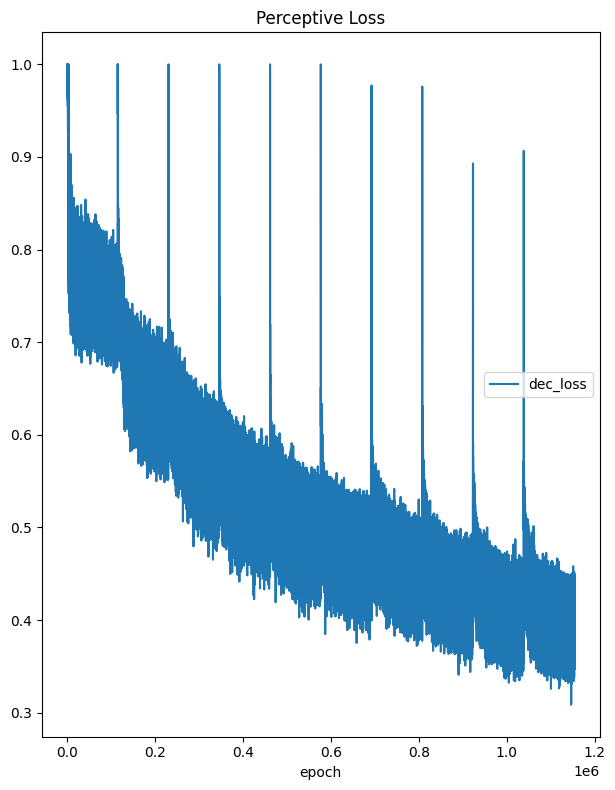

Perceptive Loss
	dec_loss         	 (min:    0.309, max:    1.000, cur:    0.407)
Encoder params: 7621680 Decoder params: 77466483 
Image params: 710453304 Compressed Image params: 7387808


In [33]:
from tqdm.autonotebook import trange
from livelossplot import PlotLosses


liveloss = PlotLosses(mode='notebook', groups={'Perceptive Loss': ['dec_loss']})

# Seeding the randomness
RANDOM_SEED=4202
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed_all(RANDOM_SEED)

# Training params
channels = image_patch_shape[0]
rounds = 2
n_deposits = 8 * rounds
pre_deposits = 1 # n_deposits // 4
n_filter = 64 * rounds // n_deposits
lat_size = 256 * rounds // n_deposits
batch_size = 64
batch_splits = 1
batch_split_size = batch_size // batch_splits
total_epochs = 256 * rounds
dep_epochs = total_epochs // n_deposits
n_epochs = dep_epochs
len_epoch = n_patches // batch_size
base_lr = 1e-4

# Building the model
encoder = Encoder(channels, n_filter, patch_size, lat_size).to(device)
decoder = Decoder(channels, n_filter, patch_size, 1, lat_size).to(device)

for _ in range(pre_deposits - 1):
    for net in [encoder, decoder]:
        grow_layers(net)

    n_epochs += dep_epochs

perceptual_loss = VGGPerceptualLoss().to(device)
optimizer = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=base_lr, betas=(0.5, 0.9), eps=1e-08, weight_decay=0, amsgrad=True)

# Loading checkpoint
checkpoint_filename = './nvd_checkpoint.pth'
log_filename = './nvd_log_history.pickle'
training_step = 0
running_dec_loss = 0.
if os.path.exists(checkpoint_filename):
    print('checkpoint found, loading...')
    checkpoint = torch.load(checkpoint_filename, 'cpu')
    training_step = checkpoint['training_step']
    running_dec_loss = checkpoint['dec_loss']

    
    while((training_step // len_epoch) > n_epochs):
        for net in [encoder, decoder]:
            grow_layers(net)

        n_epochs += dep_epochs
    
    del optimizer
    optimizer = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=base_lr, betas=(0.5, 0.9), eps=1e-08, weight_decay=0, amsgrad=True)
        
    encoder.load_state_dict(checkpoint['encoder_state_dict'])#, strict=False)
    decoder.load_state_dict(checkpoint['decoder_state_dict'])#, strict=False)
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        
    del checkpoint

    with open(log_filename, 'rb') as handle:
        log_history = pickle.load(handle)
    
    relog_history = []
    for i in range(len(log_history['dec_loss'])):
        relog_history.append({})
        for k in log_history.keys():
            relog_history[i][k] = np.clip(log_history[k][i].value, 0, 1)

    for log in relog_history:
        liveloss.update(log)

    liveloss.send()

print(f'Encoder params: {count_parameters(encoder)} Decoder params: {count_parameters(decoder)} ')
print(f'Image params: {np.prod(tensor_image_shape)} Compressed Image params: {np.prod((lat_size,) + compressed_shape)}')

torch.cuda.empty_cache()

## Training REGAE

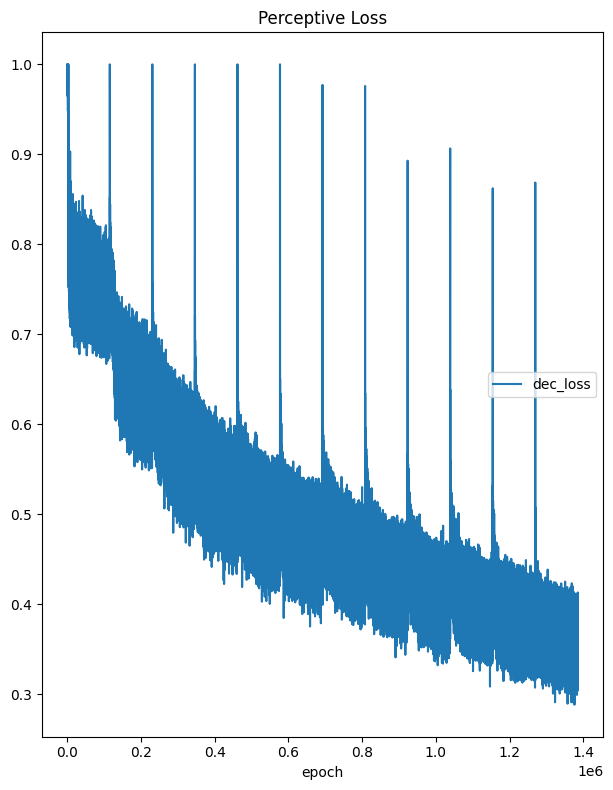

Perceptive Loss
	dec_loss         	 (min:    0.288, max:    1.000, cur:    0.381)
Depositing fresh neural vapor...
Old Encoder params: 10877808 Old Decoder params: 111115731 
New Encoder params: 12722346 New Decoder params: 130209849 
Resuming training until 416 epochs


Epoch 384:   0%|          | 0/3607 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [35]:
while (n_epochs <= total_epochs):
    for epoch in range(training_step // len_epoch, n_epochs):    
        batch_mult = batch_splits #* ((epoch // 64) + 1)
        curr_lr = base_lr #/ 2 ** (epoch // 16)
        for g in optimizer.param_groups:
            g['lr'] = curr_lr
        t = trange(training_step % len_epoch, len_epoch, desc=f'Epoch {epoch}', dynamic_ncols=True)
        for _ in t:
            # zero the parameter gradients
            optimizer.zero_grad()

            batch_dec_loss = 0.

            for m in range(batch_mult):

                # get batch
                image_patch_batch = get_random_patch_batch(batch_split_size, tensor_image)

                # computing multi-step inputs
                call_idcs = torch.randint(n_calls + 1, (batch_split_size // 2,), device=device)
                ministeps = torch.rand(batch_split_size // 2, device=device) * 1000
                bf = blend_factor(call_idcs, ministeps)[:, None, None, None]
                bf = torch.cat([bf, bf], 0)
                
                # unbiased noise sampling
                image_init = torch.randn((batch_split_size // 2, channels, patch_size, patch_size), device=device)
                image_init = torch.cat([image_init, -image_init], 0)
                
                inputs = bf * image_init + (1 - bf) * image_patch_batch

                lat_code = encoder(image_patch_batch)
                outputs = decoder(inputs, [lat_code])            
                dec_loss = (1 / batch_mult) * perceptual_loss(outputs, image_patch_batch)
                dec_loss.backward()

                batch_dec_loss += float(dec_loss.item())
            
            # update parameters
            if n_epochs > (pre_deposits * dep_epochs) and (training_step // len_epoch) % dep_epochs == 0:
                for net in [encoder, decoder]:
                    apply_gradient_mask(net, 1. - ((training_step % len_epoch) / len_epoch))
                
            optimizer.step()
            training_step += 1

            # print statistics
            running_dec_loss = 0.9 * running_dec_loss + 0.1 * batch_dec_loss

            t.set_postfix({'bm': batch_mult // batch_splits, 'lr': f'{curr_lr:.2e}' ,'dec_loss': f'{np.sqrt(running_dec_loss):.6f}'})
            liveloss.update({'dec_loss': np.sqrt(batch_dec_loss)})
        
        del image_patch_batch, call_idcs, ministeps, bf, image_init, inputs, lat_code, outputs, dec_loss
        torch.cuda.empty_cache()

        torch.save({'encoder_state_dict': encoder.state_dict(),
                    'decoder_state_dict': decoder.state_dict(),
                    'optimizer_state_dict': optimizer.state_dict(),
                    'epoch': epoch,
                    'training_step': training_step,
                    'dec_loss': running_dec_loss}, checkpoint_filename)
        
        with open(log_filename, 'wb') as handle:
            pickle.dump(liveloss.logger.log_history, handle, protocol=pickle.HIGHEST_PROTOCOL)

        liveloss.send()

    if (training_step // len_epoch) < total_epochs:
        print("Depositing fresh neural vapor...")

        if not os.path.exists(f"{Path(checkpoint_filename).stem}_{training_step // len_epoch}{Path(checkpoint_filename).suffix}"):
            shutil.copy(checkpoint_filename, f"{Path(checkpoint_filename).stem}_{training_step // len_epoch}{Path(checkpoint_filename).suffix}")
            shutil.copy(log_filename, f"{Path(log_filename).stem}_{training_step // len_epoch}{Path(log_filename).suffix}")

        print(f'Old Encoder params: {count_parameters(encoder)} Old Decoder params: {count_parameters(decoder)} ')
        for net in [encoder, decoder]:
            grow_layers(net)

        n_epochs += dep_epochs

        print(f'New Encoder params: {count_parameters(encoder)} New Decoder params: {count_parameters(decoder)} ')

        del optimizer
        optimizer = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=base_lr, betas=(0.5, 0.9), eps=1e-08, weight_decay=0, amsgrad=True)

        print(f"Resuming training until {n_epochs} epochs")
    else:
        break

In [ ]:
print(f'Encoder params: {count_parameters(encoder)} Decoder params: {count_parameters(decoder)} ')

In [ ]:
# del image_patch_batch, call_idcs, ministeps, bf, inputs, lat_code, outputs, dec_loss
# torch.cuda.empty_cache()

In [ ]:
# torch.save({'encoder_state_dict': encoder.state_dict(),
#             'decoder_state_dict': decoder.state_dict(),
#             'optimizer_state_dict': optimizer.state_dict(),
#             'epoch': epoch,
#             'training_step': training_step,
#             'dec_loss': running_dec_loss}, checkpoint_filename)

# with open(log_filename, 'wb') as handle:
#     pickle.dump(liveloss.logger.log_history, handle, protocol=pickle.HIGHEST_PROTOCOL)

## Initializing / Restoring Gencoder

In [ ]:
def update_network_average(network_tgt, network_src, beta):
    with torch.no_grad():
        param_dict_src = dict(network_src.named_parameters())

        for p_name, p_tgt in network_tgt.named_parameters():
            p_src = param_dict_src[p_name].to(p_tgt.device)
            # assert(p_src is not p_tgt)
            p_tgt.copy_(beta * p_tgt + (1. - beta) * p_src)

In [ ]:
liveloss = PlotLosses(mode='notebook', groups={'Generative Loss': ['gen_loss']})

# Seeding the randomness
RANDOM_SEED=4202
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed_all(RANDOM_SEED)

# Training params
# channels = image_patch_shape[0]
# n_filter = see_above
# lat_size = see_above
genpatch_size = 32
batch_size = 64
batch_splits = 1
batch_split_size = batch_size // batch_splits
n_epochs = 1024
len_epoch = n_patches // batch_size # (genpatch_size * batch_size)
base_lr = 1e-4

gencoder = Decoder(lat_size, lat_size, genpatch_size, 0, 0, n_filter_factor=1).to(device)
gen_optimizer = torch.optim.Adam(gencoder.parameters(), lr=base_lr, betas=(0.5, 0.9), eps=1e-08, weight_decay=0, amsgrad=True)

# Loading checkpoint
checkpoint_filename = './nvd_checkpoint_gen.pth'
log_filename = './nvd_log_history_gen.pickle'
training_step = 0
running_gen_loss = 0.
if os.path.exists(checkpoint_filename):
    print('checkpoint found, loading...')
    checkpoint = torch.load(checkpoint_filename, 'cpu')
    gencoder.load_state_dict(checkpoint['gencoder_state_dict'])
    gen_optimizer.load_state_dict(checkpoint['gen_optimizer_state_dict'])
    training_step = checkpoint['training_step']
    running_gen_loss = checkpoint['gen_loss']

    with open(log_filename, 'rb') as handle:
        log_history = pickle.load(handle)
    
    relog_history = []
    for i in range(len(log_history['gen_loss'])):
        relog_history.append({})
        for k in log_history.keys():
            relog_history[i][k] = log_history[k][i].value

    for log in relog_history:
        liveloss.update(log)

    liveloss.send()

print(f'Gencoder params: {count_parameters(gencoder)}')
print(f'Image params: {np.prod(tensor_image_shape)} Compressed Image params: {np.prod((lat_size,) + compressed_shape)}')

torch.cuda.empty_cache()

In [ ]:
# Pre-encoding image:
n_offsets = 4

tensor_image_emb_filename = 'v2_tensor_image_emb.pth'
if os.path.exists(tensor_image_emb_filename):
    print('tensor_image_emb found, loading...')
    tensor_image_emb = torch.load(tensor_image_emb_filename)['tensor_image_emb']
else:
    tensor_image_emb = torch.zeros((n_offsets, lat_size, ) + compressed_shape, device='cpu', dtype=torch.float32)
    with torch.no_grad():
        for o in trange(n_offsets):
            offset = o / n_offsets
            for x in trange(compressed_shape[0] - (1 if o > 0 else 0)):
                for y in range(compressed_shape[1] - (1 if o > 0 else 0)):
                    image_patch = get_image_patch(tensor_image, patch_size, (x + offset) / compressed_shape[0], (y + offset) / compressed_shape[1])
                    tensor_image_emb[o, :, x, y] = encoder(image_patch[None, ...])[0].to('cpu')
    
    torch.save({'tensor_image_emb': tensor_image_emb}, tensor_image_emb_filename)

print(tensor_image_emb.shape)

## Training Gencoder

In [ ]:
for epoch in range(training_step // len_epoch, n_epochs):    
    batch_mult = batch_splits * ((epoch // (n_epochs // 4)) + 1)
    curr_lr = base_lr / 2 ** (epoch // (n_epochs // 4))
    for g in optimizer.param_groups:
        g['lr'] = curr_lr
    t = trange(training_step % len_epoch, len_epoch, desc=f'Epoch {epoch} | BM: {batch_mult // batch_splits} | LR: {curr_lr}', dynamic_ncols=True)
    for b in t:
        # zero the parameter gradients
        gen_optimizer.zero_grad()

        batch_gen_loss = 0.
        
        for m in range(batch_mult):
            
            with torch.no_grad():
                origin_lat_code_batch = []
                target_lat_code_batch = []
                
                for i in range(batch_split_size):
                    o = np.random.randint(0, n_offsets)
                    x = np.random.randint(compressed_shape[0] - genpatch_size - (1 if o > 0 else 0))
                    y = np.random.randint(compressed_shape[1] - genpatch_size - (1 if o > 0 else 0))
                    origin_lat_code_batch.append(tensor_image_emb[o, :, x:x + genpatch_size, y:y + genpatch_size])
                    target_lat_code_batch.append(tensor_image_emb[(o + 1) % n_offsets, :,
                                                                   x + ((o + 1) // n_offsets):x + genpatch_size + ((o + 1) // n_offsets),
                                                                   y + ((o + 1) // n_offsets):y + genpatch_size + ((o + 1) // n_offsets)])
                    
                origin_lat_code_batch = torch.stack(origin_lat_code_batch).to(device)
                target_lat_code_batch = torch.stack(target_lat_code_batch).to(device)

            origin_lat_code_batch.requires_grad_(True)
            target_lat_code_batch.requires_grad_(True)

            # computing multi-step inputs
            call_idcs = torch.randint(n_calls + 1, (batch_split_size // 2,), device=device)
            ministeps = torch.rand(batch_split_size // 2, device=device) * 1000
            bf = blend_factor(call_idcs, ministeps)[:, None, None, None]
            bf = torch.cat([bf, bf], 0)
            
            # unbiased noise sampling
            lat_init = torch.randn((batch_split_size // 2, lat_size, genpatch_size, genpatch_size), device=device)
            lat_init = torch.cat([lat_init, -lat_init], 0)
            
            inputs = bf * lat_init + (1 - bf) * origin_lat_code_batch

            outputs = gencoder(inputs)
            gen_loss = (1 / batch_mult) * F.l1_loss(outputs, target_lat_code_batch)
            gen_loss.backward()
            
            batch_gen_loss += float(gen_loss.item())
            
        # update parameters
        gen_optimizer.step()
        training_step += 1

        # print statistics
        running_gen_loss = 0.9 * running_gen_loss + 0.1 * batch_gen_loss
        
        t.set_postfix({'gen_loss': f'{np.sqrt(running_gen_loss):.6f}'})
        liveloss.update({'gen_loss': np.sqrt(batch_gen_loss)})
        
    del origin_lat_code_batch, target_lat_code_batch, outputs, gen_loss
    torch.cuda.empty_cache()

    torch.save({'gencoder_state_dict': gencoder.state_dict(),
                'gen_optimizer_state_dict': gen_optimizer.state_dict(),
                'epoch': epoch,
                'training_step': training_step,
                'gen_loss': running_gen_loss}, checkpoint_filename)
            
    with open(log_filename, 'wb') as handle:
        pickle.dump(liveloss.logger.log_history, handle, protocol=pickle.HIGHEST_PROTOCOL)

    if (epoch + 1) % (n_epochs // 4) == 0:
        shutil.copy(checkpoint_filename, f"{Path(checkpoint_filename).stem}_{epoch + 1}{Path(checkpoint_filename).suffix}")
        shutil.copy(log_filename, f"{Path(log_filename).stem}_{epoch + 1}{Path(log_filename).suffix}")

    liveloss.send()

In [ ]:
del origin_lat_code_batch, target_lat_code_batch, outputs, gen_loss
torch.cuda.empty_cache()

In [ ]:
torch.save({'gencoder_state_dict': gencoder.state_dict(),
            'gen_optimizer_state_dict': gen_optimizer.state_dict(),
            'epoch': epoch,
            'training_step': training_step,
            'gen_loss': running_gen_loss}, checkpoint_filename)

with open(log_filename, 'wb') as handle:
    pickle.dump(liveloss.logger.log_history, handle, protocol=pickle.HIGHEST_PROTOCOL)


nvdl_names = list(get_init_params(gencoder).keys())
grow_layers(gencoder, True, [nvdl_names[0], nvdl_names[2]], [nvdl_names[-2], nvdl_names[-1]])

# n_epochs *= 2
n_epochs


## Testing

In [ ]:
import matplotlib.pyplot as plt
import cv2

def plot_patch(image_patch, x_start, x_end, y_start, y_end, patch_size, backend='matplotlib', screen_width=0, screen_height=0, txt=None, return_image=False):
    image_patch_rec = reconstruct_image_from_patch_batch(image_patch, (y_end - y_start) // patch_size, (x_end - x_start) // patch_size)
    image_patch_rec = (image_patch_rec + 1.) / 2
    image_patch_rec = image_patch_rec.to('cpu').permute(1,2,0).numpy()
    if screen_width > 0 and screen_height > 0:
        # NOTE: the following only works for even screen resolutions, otherwise... it would be odd
        if image_patch_rec.shape[0] < screen_height:
            image_patch_rec = np.tile(image_patch_rec, (int(np.ceil(screen_height / image_patch_rec.shape[0])), 1, 1))
        if image_patch_rec.shape[1] < screen_width:
            image_patch_rec = np.tile(image_patch_rec, (1, int(np.ceil(screen_width / image_patch_rec.shape[1])), 1))
        mid_h = image_patch_rec.shape[0] // 2
        mid_w = image_patch_rec.shape[1] // 2
        h_screen_height = screen_height // 2
        h_screen_width = screen_width // 2
        image_patch_rec = image_patch_rec[mid_h - h_screen_height:mid_h + h_screen_height, mid_w - h_screen_width:mid_w + h_screen_width, :]
    if backend == 'matplotlib':
        plt.figure()
        plt.imshow(image_patch_rec)
    elif backend == 'cv2' or return_image:
        image_patch_rec = cv2.cvtColor(image_patch_rec, cv2.COLOR_RGB2BGR)
        if txt:
            image_patch_rec = cv2.putText(image_patch_rec, txt, (10, screen_height - 10), cv2.FONT_HERSHEY_PLAIN, 2, (255, 255, 255), 2, cv2.LINE_AA)
        if return_image:
            return image_patch_rec
        else:
            cv2.imshow('regae', image_patch_rec)
            cv2.waitKey(int(1000/30))
    else:
        raise RuntimeError('unknown backend '+ backend)

In [ ]:
sample_batch_size = 1024

def plot_lat_code_batch(lat_code_batch, x_start, x_end, y_start, y_end, patch_size, backend='matplotlib', screen_width=0, screen_height=0, txt=None, return_image=False):
    lat_code_batch_rec = lat_code_batch[0].reshape(lat_size, lat_code_batch.shape[2] * lat_code_batch.shape[3]).permute(1, 0)
    decompressed_patch = torch.randn((lat_code_batch_rec.shape[0], ) + image_patch_shape, device=device)
    n_batches = int(np.ceil(lat_code_batch_rec.shape[0] / sample_batch_size))
    for b in range(n_batches):
        lat_code = lat_code_batch_rec[b * sample_batch_size: (b + 1) * sample_batch_size]
        decompressed_patch[b * sample_batch_size: (b + 1) * sample_batch_size] = requantize(decoder(decompressed_patch[b * sample_batch_size: (b + 1) * sample_batch_size], [lat_code]))
    
    # decompressed_patch[:, :, :, -1] = 1.
    # decompressed_patch[:, :, -1, :] = 1.
    
    image_patch = plot_patch(decompressed_patch, x_start, x_end, y_start, y_end, patch_size, backend, screen_width, screen_height, txt, return_image)
    if return_image:
        return (image_patch * 255).astype(np.uint8)

In [ ]:
import time
import subprocess

def suspend_screensaver():
    'suspend linux screensaver'
    proc = subprocess.Popen('gsettings set org.gnome.desktop.screensaver idle-activation-enabled false', shell=True)
    proc.wait()

def resume_screensaver():
    'resume linux screensaver'
    proc = subprocess.Popen('gsettings set org.gnome.desktop.screensaver idle-activation-enabled true', shell=True)
    proc.wait()


In [ ]:
x_start = 2280
x_end = 2280 + 1024
y_start = 2280
y_end = 2280 + 1024
with torch.no_grad():
    image_patch = get_patch_any_size(tensor_image, x_start, x_end, y_start, y_end)
    plot_patch(image_patch, x_start, x_end, y_start, y_end, patch_size)

In [ ]:
with torch.no_grad():    
    decompressed_patch = torch.randn((image_patch.shape[0], ) + image_patch_shape, device=device)
    n_batches = image_patch.shape[0] // batch_size
    for b in range(n_batches):
        lat_code = encoder(image_patch[b * batch_size: (b + 1) * batch_size])
        decompressed_patch[b * batch_size: (b + 1) * batch_size] = requantize(decoder(decompressed_patch[b * batch_size: (b + 1) * batch_size], [lat_code]))
    
    plot_patch(decompressed_patch, x_start, x_end, y_start, y_end, patch_size)

In [ ]:
decomp_error = (image_patch - decompressed_patch)
#decomp_error = (decomp_error - decomp_error.mean()) / decomp_error.std()
plot_patch(decomp_error, x_start, x_end, y_start, y_end, patch_size)
decomp_error.abs().mean()

In [ ]:
with torch.no_grad():    
    decompressed_patch = torch.randn((image_patch.shape[0], ) + image_patch_shape, device=device)
    n_batches = image_patch.shape[0] // batch_size
    for b in range(n_batches):
        lat_code = torch.randn_like(lat_code)
        decompressed_patch[b * batch_size: (b + 1) * batch_size] = requantize(decoder(decompressed_patch[b * batch_size: (b + 1) * batch_size], [lat_code]))
    
    plot_patch(decompressed_patch, x_start, x_end, y_start, y_end, patch_size)

In [ ]:
del image_patch, lat_code, decompressed_patch, decomp_error
torch.cuda.empty_cache()

In [ ]:
with torch.no_grad():
    lat_code_batch = get_image_patch(tensor_image_emb[0], genpatch_size, (x_start/patch_size) / compressed_shape[0], (y_start/patch_size) / compressed_shape[1])[None, ...]
    plot_lat_code_batch(lat_code_batch, x_start, x_end, y_start, y_end, patch_size)

In [ ]:
with torch.no_grad():
    lat_code_batch = get_image_patch(tensor_image_emb[0], genpatch_size, (x_start/patch_size) / compressed_shape[0], (y_start/patch_size) / compressed_shape[1])[None, ...]
    lat_code_batch = gencoder(lat_code_batch)
    plot_lat_code_batch(lat_code_batch, x_start, x_end, y_start, y_end, patch_size)

In [ ]:
lat_code_batch.mean(), lat_code_batch.std()

In [ ]:
del lat_code_batch
torch.cuda.empty_cache()

In [ ]:
def shift_bit_length(x):
    return 1<<(x-1).bit_length()

with torch.no_grad():    
    # screen_width, screen_height = 1920, 1080
    screen_width, screen_height = 1024, 1024
    canvas_size = genpatch_size # shift_bit_length(round(min(screen_height, screen_width) / patch_size))
    
    lat_code_batch = torch.randn((1, lat_size, canvas_size, canvas_size), device=device)
    for n in range(n_calls):
        bf = blend_factor(n)
        lat_code_batch = gencoder(bf * torch.randn_like(lat_code_batch) + (1 - bf) * lat_code_batch)
    
    bf_mask = (n_calls - 1) * torch.ones((1, 1, canvas_size, canvas_size), device=device) #
    n_calls_offset = 4
    for c in range(n_calls - n_calls_offset):
        bf_mask[:, :, canvas_size-1-c:canvas_size-1-c+1, :canvas_size-1-c+1] = c + n_calls_offset
        bf_mask[:, :, :canvas_size-1-c+1, canvas_size-1-c:canvas_size-1-c+1] = c + n_calls_offset
    
    bf_mask = blend_factor(bf_mask) * torch.rand_like(bf_mask)
    
    suspend_screensaver()
    cv2.namedWindow("regae", cv2.WINDOW_NORMAL)
    # cv2.setWindowProperty("regae", cv2.WND_PROP_FULLSCREEN, cv2.WINDOW_FULLSCREEN)
    for n in range(n_offsets * canvas_size * 4):
        # bf_mask = blend_factor(1 + (n % (n_calls - n_calls_offset)))
        lat_code_batch = gencoder(bf_mask * torch.randn_like(lat_code_batch) + (1 - bf_mask) * lat_code_batch)
        # lat_code_batch = gencoder(lat_code_batch)
        batch_norm = lat_code_batch.pow(2).mean().item()
        # print(lat_code_batch.pow(2).mean())
        plot_lat_code_batch(lat_code_batch, 0, canvas_size * patch_size, 0, canvas_size * patch_size, patch_size, 'cv2', screen_width, screen_height, F'{batch_norm:0.6f}')
        # print('step: ', n)
    
    # plot_lat_code_batch(lat_code_batch, x_start, x_end, y_start, y_end, patch_size)

#cv2.waitKey(0)
cv2.destroyAllWindows()
resume_screensaver()

del lat_code_batch, bf_mask
torch.cuda.empty_cache()

In [ ]:
cv2.destroyAllWindows()
resume_screensaver()

del lat_code_batch, bf_mask
torch.cuda.empty_cache()

In [ ]:
with torch.no_grad():    
    # screen_width, screen_height = 2446, 1024
    screen_width, screen_height = 1920, 1080
    canvas_height = int(np.ceil(screen_height / patch_size))
    canvas_width = int(np.ceil(screen_width / patch_size))
    
    lat_code_batch = torch.randn((1, lat_size, canvas_height, canvas_width), device=device)
    for n in range(n_calls):
        for j in [int(y) for y in np.linspace(0, canvas_height - genpatch_size, int(np.ceil(canvas_height / genpatch_size)), endpoint=True)]:
            for i in [int(x) for x in np.linspace(0, canvas_width - genpatch_size, int(np.ceil(canvas_width / genpatch_size)), endpoint=True)]:
                bf = blend_factor(n)
                lat_code_batch_tile = lat_code_batch[:, :, j:j + genpatch_size, i:i+genpatch_size]
                lat_code_batch[:, :, j:j + genpatch_size, i:i+genpatch_size].copy_(gencoder(bf * torch.randn_like(lat_code_batch_tile) + (1 - bf) * lat_code_batch_tile))

    lat_code_batch_new = torch.empty((1, lat_size, canvas_height, canvas_width), device=device)
    
    n_calls_offset = 4
    bf_mask = (n_calls - 1) * torch.ones((1, 1, canvas_height, canvas_width), device=device)
    for c in range(n_calls - n_calls_offset):
        bf_mask[:, :, canvas_height-1-c:canvas_height-1-c+1, :canvas_width-1-c+1] = c + n_calls_offset
        bf_mask[:, :, :canvas_height-1-c+1, canvas_width-1-c:canvas_width-1-c+1] = c + n_calls_offset
    
    bf_mask = blend_factor(bf_mask) * torch.rand_like(bf_mask)
    
    suspend_screensaver()
    cv2.namedWindow("regae", cv2.WINDOW_NORMAL)
    cv2.setWindowProperty("regae", cv2.WND_PROP_FULLSCREEN, cv2.WINDOW_FULLSCREEN)
    for n in range(n_offsets * 8 * screen_height // patch_size):
        for j in [int(y) for y in np.linspace(0, canvas_height - genpatch_size, int(np.ceil(canvas_height / genpatch_size) * 1.5), endpoint=True)]:
            for i in [int(x) for x in np.linspace(0, canvas_width - genpatch_size, int(np.ceil(canvas_width / genpatch_size) * 1.5), endpoint=True)]:
                # bf_mask = blend_factor(1 + (n % (n_calls - n_calls_offset)))
                bf_mask_tile = bf_mask[:, :, j:j + genpatch_size, i:i+genpatch_size]
                lat_code_batch_tile = lat_code_batch[:, :, j:j + genpatch_size, i:i+genpatch_size]
                lat_code_batch_new[:, :, j:j + genpatch_size, i:i+genpatch_size].copy_(gencoder(bf_mask_tile * torch.randn_like(lat_code_batch_tile) + (1 - bf_mask_tile) * lat_code_batch_tile))
                # lat_code_batch_new[:, :, j:j + genpatch_size, i:i+genpatch_size].copy_(gencoder(lat_code_batch_tile))

        lat_code_batch.copy_(lat_code_batch_new)
        #if n > n_offsets * screen_height // patch_size:
        plot_lat_code_batch(lat_code_batch, 0, canvas_width * patch_size, 0, canvas_height * patch_size, patch_size, 'cv2', screen_width, screen_height)
        # print('step: ', n)
    
    # plot_lat_code_batch(lat_code_batch, x_start, x_end, y_start, y_end, patch_size)

# cv2.waitKey(0)
cv2.destroyAllWindows()
resume_screensaver()

del lat_code_batch, lat_code_batch_new, lat_code_batch_tile, bf_mask, bf_mask_tile
torch.cuda.empty_cache()

In [ ]:
with torch.no_grad():    
    # screen_width, screen_height = 2446, 1024
    screen_width, screen_height = 1920, 1080
    canvas_height = int(np.ceil(screen_height / patch_size))
    canvas_width = int(np.ceil(screen_width / patch_size))
    
    lat_code_batch = torch.randn((1, lat_size, canvas_height, canvas_width), device=device)
    for n in range(n_calls):
        for j in [int(y) for y in np.linspace(0, canvas_height - genpatch_size, int(np.ceil(canvas_height / genpatch_size)), endpoint=True)]:
            for i in [int(x) for x in np.linspace(0, canvas_width - genpatch_size, int(np.ceil(canvas_width / genpatch_size)), endpoint=True)]:
                bf = blend_factor(n)
                lat_code_batch_tile = lat_code_batch[:, :, j:j + genpatch_size, i:i+genpatch_size]
                lat_code_batch[:, :, j:j + genpatch_size, i:i+genpatch_size].copy_(gencoder(bf * torch.randn_like(lat_code_batch_tile) + (1 - bf) * lat_code_batch_tile))

    lat_code_batch_new = torch.empty((1, lat_size, canvas_height, canvas_width), device=device)
    
    bf_mask = (n_calls - 1) * torch.ones((1, 1, genpatch_size, genpatch_size), device=device)
    for c in range(n_calls - n_calls_offset):
        bf_mask[:, :, genpatch_size-1-c:genpatch_size-1-c+1, :genpatch_size-1-c+1] = c + n_calls_offset
        bf_mask[:, :, :genpatch_size-1-c+1, genpatch_size-1-c:genpatch_size-1-c+1] = c + n_calls_offset
    
    bf_mask = blend_factor(bf_mask) * torch.rand_like(bf_mask)

    bf_mask_r =  torch.rand((1, 1, genpatch_size, genpatch_size), device=device)

    suspend_screensaver()
    cv2.namedWindow("regae", cv2.WINDOW_NORMAL)
    cv2.setWindowProperty("regae", cv2.WND_PROP_FULLSCREEN, cv2.WINDOW_FULLSCREEN)
    running_minutes = 4
    start_time = time.time()
    current_time = start_time
    while (current_time - start_time) / 60 < (running_minutes + 1):
        current_time = time.time()
        bf_mask = (n_calls - 1) * torch.ones((1, 1, genpatch_size, genpatch_size), device=device)
        n_calls_offset = 1 + int((n_calls - 1) * ((current_time - start_time) / 60) / running_minutes)
        for c in range(n_calls - n_calls_offset):
            bf_mask[:, :, genpatch_size-1-c:genpatch_size-1-c+1, :genpatch_size-1-c+1] = c + n_calls_offset
            bf_mask[:, :, :genpatch_size-1-c+1, genpatch_size-1-c:genpatch_size-1-c+1] = c + n_calls_offset
        
        bf_mask = blend_factor(bf_mask) * bf_mask_r
        for j in [int(y) for y in np.linspace(0, canvas_height - genpatch_size, int(np.ceil(canvas_height / genpatch_size)), endpoint=True)]:
            for i in [int(x) for x in np.linspace(0, canvas_width - genpatch_size, int(np.ceil(canvas_width / genpatch_size)), endpoint=True)]:
                # bf_mask = blend_factor(1 + (n % (n_calls - n_calls_offset)))
                lat_code_batch_tile = lat_code_batch[:, :, j:j + genpatch_size, i:i+genpatch_size]
                lat_code_batch_new[:, :, j:j + genpatch_size, i:i+genpatch_size].copy_(gencoder(bf_mask * torch.randn_like(lat_code_batch_tile) + (1 - bf_mask) * lat_code_batch_tile))

        lat_code_batch.copy_(lat_code_batch_new)
        #if n > n_offsets * screen_height // patch_size:
        plot_lat_code_batch(lat_code_batch, 0, canvas_width * patch_size, 0, canvas_height * patch_size, patch_size, 'cv2', screen_width, screen_height)
        # print('step: ', n)
    
    # plot_lat_code_batch(lat_code_batch, x_start, x_end, y_start, y_end, patch_size)

# cv2.waitKey(0)
cv2.destroyAllWindows()
resume_screensaver()

del lat_code_batch, lat_code_batch_new, bf_mask, lat_code_batch_tile
torch.cuda.empty_cache()

In [ ]:
cv2.destroyAllWindows()
resume_screensaver()
del lat_code_batch, lat_code_batch_new, lat_code_batch_tile, bf_mask, bf_mask_tile
# del lat_code_batch, lat_code_batch_new, bf_mask, lat_code_batch_tile
torch.cuda.empty_cache()

In [ ]:
from datetime import datetime

with torch.no_grad():    
    # screen_width, screen_height = 2446, 1024
    screen_width, screen_height = 1920, 1080
    fps = 16
    canvas_height = int(np.ceil(screen_height / patch_size))
    canvas_width = int(np.ceil(screen_width / patch_size))
    
    lat_code_batch = torch.randn((1, lat_size, canvas_height, canvas_width), device=device)
    for n in range(n_calls):
        for j in [int(y) for y in np.linspace(0, canvas_height - genpatch_size, int(np.ceil(canvas_height / genpatch_size)), endpoint=True)]:
            for i in [int(x) for x in np.linspace(0, canvas_width - genpatch_size, int(np.ceil(canvas_width / genpatch_size)), endpoint=True)]:
                bf = blend_factor(n)
                lat_code_batch_tile = lat_code_batch[:, :, j:j + genpatch_size, i:i+genpatch_size]
                lat_code_batch[:, :, j:j + genpatch_size, i:i+genpatch_size].copy_(gencoder(bf * torch.randn_like(lat_code_batch_tile) + (1 - bf) * lat_code_batch_tile))

    lat_code_batch_new = torch.empty((1, lat_size, canvas_height, canvas_width), device=device)
    
    # n_calls_offset = 4
    # bf_mask = (n_calls - 1) * torch.ones((1, 1, canvas_height, canvas_width), device=device)
    # for c in range(n_calls - n_calls_offset):
    #     bf_mask[:, :, canvas_height-1-c:canvas_height-1-c+1, :canvas_width-1-c+1] = c + n_calls_offset
    #     bf_mask[:, :, :canvas_height-1-c+1, canvas_width-1-c:canvas_width-1-c+1] = c + n_calls_offset
    
    # bf_mask = blend_factor(bf_mask)

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # Codec for .mp4 format
    video_writer = cv2.VideoWriter(f'npc_{datetime.now().strftime("%y%m%d_%H:%M:%S")}.mp4', fourcc, fps, (screen_width, screen_height))
    
    for n in trange(4 * n_offsets * 8 * screen_height // patch_size):
        for j in [int(y) for y in np.linspace(0, canvas_height - genpatch_size, int(np.ceil(canvas_height / genpatch_size) * 1.5), endpoint=True)]:
            for i in [int(x) for x in np.linspace(0, canvas_width - genpatch_size, int(np.ceil(canvas_width / genpatch_size) * 1.5), endpoint=True)]:
                # bf_mask = blend_factor(1 + (n % (n_calls - n_calls_offset)))
                # bf_mask_tile = bf_mask[:, :, j:j + genpatch_size, i:i+genpatch_size]
                lat_code_batch_tile = lat_code_batch[:, :, j:j + genpatch_size, i:i+genpatch_size]
                # lat_code_batch_new[:, :, j:j + genpatch_size, i:i+genpatch_size].copy_(gencoder(bf_mask_tile * torch.randn_like(lat_code_batch_tile) + (1 - bf_mask_tile) * lat_code_batch_tile))
                lat_code_batch_new[:, :, j:j + genpatch_size, i:i+genpatch_size].copy_(gencoder(lat_code_batch_tile))

        lat_code_batch.copy_(lat_code_batch_new)
        #if n > n_offsets * screen_height // patch_size:
        image = plot_lat_code_batch(lat_code_batch, 0, canvas_width * patch_size, 0, canvas_height * patch_size, patch_size, 'cv2', screen_width, screen_height, return_image=True)
        # print('step: ', n)
        video_writer.write(image)
    
    # plot_lat_code_batch(lat_code_batch, x_start, x_end, y_start, y_end, patch_size)

    video_writer.release()


del lat_code_batch, lat_code_batch_new, lat_code_batch_tile#, bf_mask, bf_mask_tile
torch.cuda.empty_cache()